In [76]:
import matplotlib.pyplot as plt
import pandas as pd
from pandas import DataFrame

In [77]:
DATA = pd.read_csv('iterations.csv')
df = DATA[['ngen','fitness','parameters']] 
#df = data[data['fitness'] < 0.81]
print(df.shape)

(6056, 3)


In [78]:
from mass_action import MAPFactory, MAParameters, MassAction, plot_trajectory
import ast

FACTORY = MAPFactory()

ea_trajectories = []
trajectory = []
num = 0 
for index, row in df.iterrows():
    #print(index)
    fitness = (row['fitness'])
    ngen = (row['ngen'])
    if ngen == 1:
        if trajectory:
            ea_trajectories.append(trajectory)
        trajectory = []
    trajectory.append((ngen,fitness))

    """
    l = ast.literal_eval(row['parameters'])
    p = FACTORY.from_list(l)
    model = MassAction(p)
    plot_trajectory(model)
    """
  

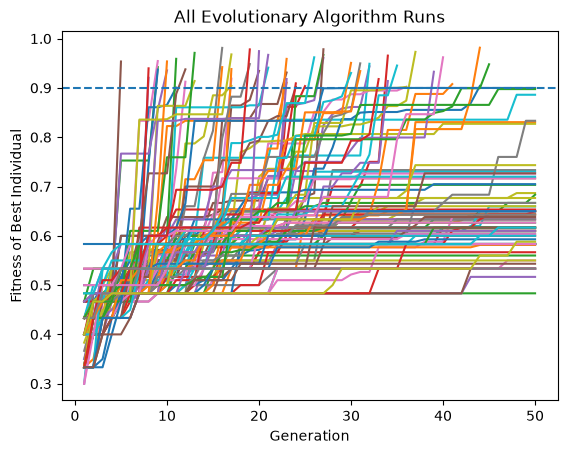

In [79]:
for trajectory in ea_trajectories:
    x, y = zip(*trajectory)
    plt.plot(x,y)
    plt.title("All Evolutionary Algorithm Runs")
    plt.xlabel("Generation")
    plt.ylabel("Fitness of Best Individual")
plt.axhline(y=0.9,linestyle="--")


plt.savefig("figures/all_trajectories.png")
plt.show()

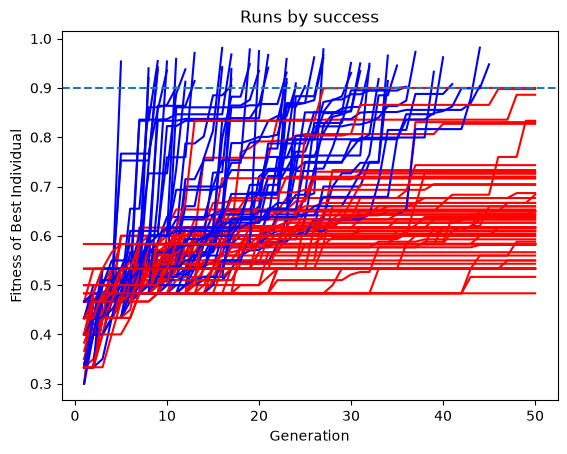

In [80]:
for trajectory in ea_trajectories:
    if trajectory[-1][1] > 0.9:
        color = 'blue'
    else:
        color = 'red'
    plt.title("Runs by success")
    plt.xlabel("Generation")
    plt.ylabel("Fitness of Best Individual")
    x, y = zip(*trajectory)
    plt.plot(x,y, color=color)
plt.axhline(y=0.9,linestyle="--")

plt.savefig("figures/colored_trajectories.png")
plt.show()

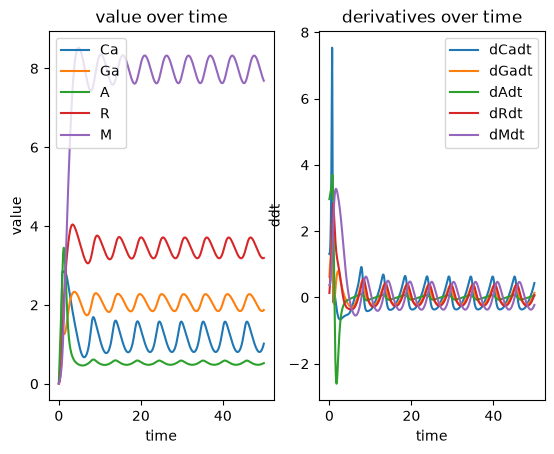

In [81]:
def plot_by_index(i, file=None):
    row = DATA.iloc[i]
    l = ast.literal_eval(row['parameters'])
    p = FACTORY.from_list(l)
    model = MassAction(p)
    plot_trajectory(model,save_file=file)

plot_by_index(3200)

In [82]:
df_osc = df[df['fitness'] > 0.90]
"""
for i, row in df_osc.iterrows():
    plot_by_index(i,file=f'figures/osc/{i}.png')
"""

"\nfor i, row in df_osc.iterrows():\n    plot_by_index(i,file=f'figures/osc/{i}.png')\n"

(6056, 22)


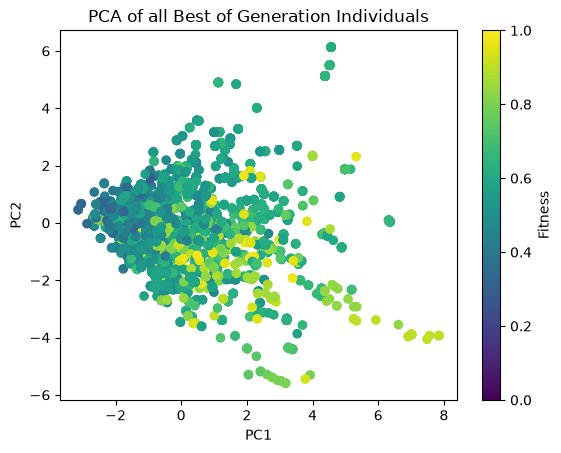

In [83]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# X: DataFrame containing the features for PCA
# df['additional_feature']: values between 0 and 1
fitnesses = []
X = DataFrame(columns=list(range(22)))
for i, row in DATA.iterrows():
    features = ast.literal_eval(row['parameters'])
    fitness = row['fitness']
    fitnesses.append(fitness)
    X.loc[len(X)] = features

print(X.shape)

X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

fig, ax = plt.subplots()

sc = ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=fitnesses,
    cmap='viridis',
    vmin=0,
    vmax=1
)

fig.colorbar(sc, ax=ax, label='Fitness')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
plt.title('PCA of all Best of Generation Individuals')

plt.savefig('figures/pca.png')
plt.show()

In [84]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=X.columns,
    columns=['PC1', 'PC2']
)
loadings

,PC1,PC2
0,0.028495,-0.010388
1,0.222529,-0.182163
2,0.167228,0.412691
3,0.249511,-0.373201
4,0.133352,-0.048127
5,0.184107,0.038987
6,0.167810,-0.323585
7,0.208351,0.160411
8,0.355010,-0.203288
9,0.274207,-0.008113


In [100]:
from sklearn.linear_model import LinearRegression
import numpy as np

for i, row in X.T.iterrows():
    model = LinearRegression()
    a = np.array(row).reshape(-1,1)
    print(i)
    model.fit(a, np.array(fitnesses))
    score = model.score(a,np.array(fitnesses))
    print(score)
    
#Conclusion: poor correlation between fitness and individual parameters

0
0.01550286917261301
1
0.014487688589737924
2
0.014528125710818074
3
0.2089020601041871
4
0.0001330467495137544
5
0.09974365053524847
6
0.09372267256506106
7
0.0034018753029363413
8
0.07020673201802075
9
0.005866659732144286
10
0.018622743521212515
11
0.027154997486593335
12
0.007101872983592883
13
0.00519362261483669
14
0.003980019218731701
15
0.024965893109907045
16
0.08410285285617103
17
1.7120744845611213e-05
18
0.028891907858416443
19
0.014977523621677147
20
0.010629286899309975
21
0.0677773253433378


In [86]:
#TODO Distribution of optimal parameters
#boxplots where each box is a 
# For osc